# Model selection and tuning without labels

A typical unsupervised workflow: you fit detectors on unlabeled data,
tune their hyperparameters, pick one, and deploy it. Without labels, both
the tuning and the pick need a label-free criterion. This notebook

1. tunes four detector families with Optuna, using a label-free metric as
   the objective,
2. selects one of the tuned detectors by combining several label-free
   metrics with robust Borda counting,
3. and measures the selected detector on a labeled test split it never saw,
   first on one dataset and then on several.

Install the dependencies with `pip install "labelfree[examples]"`.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
from oddball import load
from pyod.models.knn import KNN
from pyod.models.lof import LOF
from sklearn.base import clone
from sklearn.ensemble import IsolationForest
from sklearn.metrics import average_precision_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import OneClassSVM

import labelfree as lf

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option("display.precision", 3)

## Data

We split the dataset in half. The training half is treated as unlabeled:
it contains anomalies, but nothing below uses its labels. The test half
keeps its labels and is used only to measure the final choice. Training
data is capped at 600 rows to keep tuning fast.

In [2]:
CONTAMINATION = 0.10  # prior guess of the anomaly share
MAX_TRAIN = 600


def load_split(dataset, seed=0):
    X, y = load(dataset)
    y = (y != 0).astype(int)
    X_train, X_test, _, y_test = train_test_split(
        X, y, test_size=0.5, stratify=y, random_state=seed
    )
    X_train = X_train[: min(MAX_TRAIN, len(X_train))]
    scaler = StandardScaler().fit(X_train)
    return scaler.transform(X_train), scaler.transform(X_test), y_test


X_train, X_test, y_test = load_split("cardio")
print(f"train: {X_train.shape} without labels, test: {X_test.shape} with labels")

train: (600, 21) without labels, test: (916, 21) with labels


## Search spaces

Each detector family gets a small search space. scikit-learn detectors
score normal samples higher, PyOD detectors score anomalies higher; the
`score_polarity` tells `labelfree` which is which.

In [3]:
FAMILIES = {
    "iforest": (
        lambda t: IsolationForest(
            max_samples=t.suggest_int("max_samples", 16, 512, log=True),
            max_features=t.suggest_float("max_features", 0.3, 1.0),
            random_state=0,
        ),
        "higher_is_normal",
    ),
    "ocsvm": (
        lambda t: OneClassSVM(
            nu=t.suggest_float("nu", 0.01, 0.5, log=True),
            gamma=t.suggest_float("gamma", 1e-3, 1.0, log=True),
        ),
        "higher_is_normal",
    ),
    "lof": (
        lambda t: LOF(n_neighbors=t.suggest_int("n_neighbors", 3, 100, log=True)),
        "higher_is_anomalous",
    ),
    "knn": (
        lambda t: KNN(
            n_neighbors=t.suggest_int("n_neighbors", 1, 100, log=True),
            method=t.suggest_categorical("method", ["largest", "mean", "median"]),
        ),
        "higher_is_anomalous",
    ),
}

## Step 1: tune each family with a label-free objective

The objective fits a configuration on the training data and returns its
SIREOS value on the same data. SIREOS is cheap, compares well across
detectors, and checks that high-scoring samples are isolated in feature
space; lower is better. `unify_scores` maps the raw scores to the
non-negative outlier probabilities SIREOS needs. Any other metric, or a
combination, can be dropped in here.

In [4]:
def objective(X, make_model, polarity):
    def evaluate(trial):
        model = make_model(trial).fit(X)
        probabilities = lf.unify_scores(
            model.decision_function(X), score_polarity=polarity
        )
        if probabilities.sum() == 0:  # constant scores flag nothing
            return float("inf")
        return lf.sireos_score(X, probabilities)

    return evaluate


def tune(X, n_trials=25, seed=0):
    tuned = {}
    for family, (make_model, polarity) in FAMILIES.items():
        study = optuna.create_study(
            direction="minimize", sampler=optuna.samplers.TPESampler(seed=seed)
        )
        study.optimize(objective(X, make_model, polarity), n_trials=n_trials)
        model = make_model(optuna.trial.FixedTrial(study.best_params)).fit(X)
        tuned[family] = (model, polarity, study.best_params)
    return tuned


tuned = tune(X_train)
pd.Series(
    {
        family: {k: round(v, 3) if isinstance(v, float) else v for k, v in p.items()}
        for family, (_, _, p) in tuned.items()
    },
    name="best parameters",
).to_frame()

,best parameters
iforest,"{'max_samples': 423, 'max_features': 0.86}"
ocsvm,"{'nu': 0.481, 'gamma': 0.001}"
lof,{'n_neighbors': 99}
knn,"{'n_neighbors': 65, 'method': 'mean'}"


## Step 2: select one detector

The four tuned detectors now compete. One metric alone is noisy, so we
score each detector with several label-free metrics that work across
detector families and combine their rankings with
`robust_borda_scores` (Goswami et al., 2023), which drops the metrics that
disagree most with the consensus. The candidates are the tuned detectors
plus each family's default configuration.

In [5]:
DEFAULTS = {
    "iforest": (IsolationForest(random_state=0), "higher_is_normal"),
    "ocsvm": (OneClassSVM(), "higher_is_normal"),
    "lof": (LOF(), "higher_is_anomalous"),
    "knn": (KNN(), "higher_is_anomalous"),
}
SELECTION_METRICS = {  # name: higher is better
    "asoi": True,
    "laplacian": False,
    "sireos": False,
    "mc": True,
    "hits": True,
}


def candidate_pool(X, tuned):
    pool = {f"{f} tuned": (model, pol) for f, (model, pol, _) in tuned.items()}
    for family, (model, polarity) in DEFAULTS.items():
        pool[f"{family} default"] = (clone(model).fit(X), polarity)
    return pool


def selection_table(X, pool):
    scores = np.vstack(
        [
            lf.orient_scores(model.decision_function(X), score_polarity=polarity)
            for model, polarity in pool.values()
        ]
    )
    table = pd.DataFrame(
        {
            "asoi": [lf.asoi_score(X, s, contamination=CONTAMINATION) for s in scores],
            "laplacian": [lf.laplacian_score(X, s, n_neighbors=10) for s in scores],
            "sireos": [lf.sireos_score(X, lf.unify_scores(s)) for s in scores],
            "mc": lf.model_centrality_scores(scores),
            "hits": lf.hits_scores(scores),
        },
        index=list(pool),
    )
    table["borda"] = lf.robust_borda_scores(
        table[list(SELECTION_METRICS)].T.to_numpy(),
        higher_is_better=list(SELECTION_METRICS.values()),
    )
    return table.sort_values("borda", ascending=False)


pool = candidate_pool(X_train, tuned)
selection = selection_table(X_train, pool)
selection

,asoi,laplacian,sireos,mc,hits,borda
iforest tuned,4.428,0.388,0.023,0.711,0.313,15.0
lof tuned,4.428,0.544,0.017,0.707,0.377,15.0
ocsvm tuned,4.503,0.589,0.017,0.623,0.377,14.0
knn tuned,4.510,0.434,0.018,0.688,0.378,14.0
ocsvm default,4.517,0.402,0.024,0.692,0.378,13.0
iforest default,4.401,0.356,0.026,0.702,0.245,8.0
knn default,4.201,0.548,0.023,0.571,0.377,5.0
lof default,3.902,0.730,0.029,0.531,0.359,0.0


## Step 3: performance on the labeled test split

Now the labels come in. Each candidate scores the unseen test split and we
compute its average precision (AP). The bar of the label-free pick is
highlighted; the dashed line marks the default Isolation Forest, a common
choice when nothing better is known.

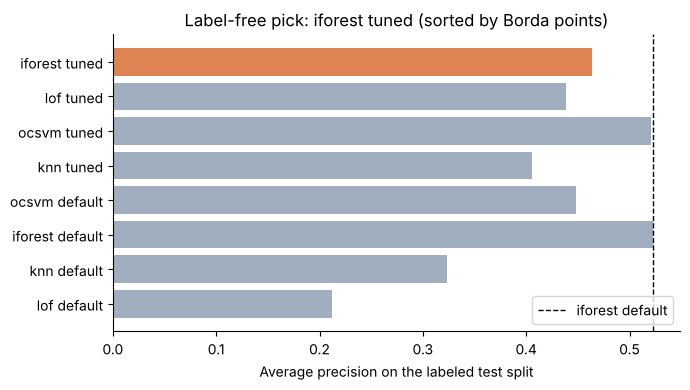

In [6]:
def test_ap(pool, X_test, y_test):
    return pd.Series(
        {
            name: average_precision_score(
                y_test,
                lf.orient_scores(model.decision_function(X_test), score_polarity=pol),
            )
            for name, (model, pol) in pool.items()
        }
    )


ap = test_ap(pool, X_test, y_test).loc[selection.index]
pick = selection.index[0]

fig, ax = plt.subplots(figsize=(7, 4))
colors = ["#DD8452" if name == pick else "#A0AEC0" for name in ap.index]
ax.barh(ap.index[::-1], ap[::-1], color=colors[::-1])
ax.axvline(
    ap["iforest default"],
    color="black",
    linestyle="--",
    linewidth=1,
    label="iforest default",
)
ax.legend(loc="lower right")
ax.set_xlabel("Average precision on the labeled test split")
ax.set_title(f"Label-free pick: {pick} (sorted by Borda points)")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()

## Does this hold on other datasets?

One dataset proves little. The function below repeats the whole workflow,
tuning, selection, and test evaluation, for several datasets and compares
the label-free pick with three references: the default Isolation Forest,
the median candidate, and the best candidate in hindsight (the oracle,
which needs labels).

In [7]:
def run_workflow(dataset, seed=0):
    X_train, X_test, y_test = load_split(dataset, seed)
    pool = candidate_pool(X_train, tune(X_train, seed=seed))
    selection = selection_table(X_train, pool)
    ap = test_ap(pool, X_test, y_test)
    return {
        "dataset": dataset,
        "pick": selection.index[0],
        "pick_ap": ap[selection.index[0]],
        "iforest_default_ap": ap["iforest default"],
        "median_ap": ap.median(),
        "oracle_ap": ap.max(),
    }


DATASETS = ["cardio", "breastw", "thyroid", "wbc", "pima", "annthyroid"]
results = pd.DataFrame([run_workflow(dataset) for dataset in DATASETS]).set_index(
    "dataset"
)
results

,pick,pick_ap,iforest_default_ap,median_ap,oracle_ap
dataset,,,,,
cardio,iforest tuned,0.463,0.523,0.444,0.523
breastw,iforest tuned,0.988,0.976,0.910,0.988
thyroid,knn tuned,0.577,0.634,0.603,0.675
wbc,iforest default,1.000,1.000,0.883,1.000
pima,knn tuned,0.506,0.470,0.472,0.513
annthyroid,ocsvm tuned,0.270,0.351,0.322,0.401


In [8]:
summary = pd.Series(
    {
        "pick beats default iforest": (
            results["pick_ap"] > results["iforest_default_ap"]
        ).sum(),
        "pick beats median candidate": (
            results["pick_ap"] > results["median_ap"]
        ).sum(),
        "datasets": len(results),
    }
)
summary.to_frame("count")

,count
pick beats default iforest,2
pick beats median candidate,4
datasets,6


## Takeaways

- Label-free tuning and selection is a complete, label-free pipeline: every
  decision above used only the training data.
- Whether it beats a sensible default depends on the dataset. Ma et al.
  (2023) found that no internal criterion wins reliably across many
  datasets, so compare the label-free pick with a default on your own data
  whenever a few labels are available.
- To explore which metrics carry signal on a dataset, see the
  [metric comparison notebook](metric_comparison.ipynb).